**Correction:** An earlier run selected constant genes due to numerical precision and is superseded. This run uses float64 preprocessing and removes constant features inside each training fold.

# BioVis-Cancer: reproducible exploratory evaluation

This notebook runs the revised evaluation in `evaluate.py`. It does not reproduce the historical metrics. It requires a local GDC cohort downloaded with `python download_gdc.py`; patient-derived expression data is not synthetic and must not be committed. This project is research software, not a clinical tool.

In [1]:
from pathlib import Path
import sys
root = Path.cwd() if (Path.cwd() / "evaluate.py").exists() else Path.cwd().parent
if not (root / "evaluate.py").exists():
    raise RuntimeError("Run from the repository root or notebooks directory.")
import os
os.chdir(root)
sys.path.insert(0, str(root))
from evaluate import main
main()

Cohort: 503 cases, 60660 genes. Train: 402, test: 101.


Running three-fold cross-validation on training cases...


Fitting on training cases and evaluating held-out cases...


              precision    recall  f1-score   support

           0       0.66      0.82      0.73        55
           1       0.44      0.33      0.38        24
           2       0.25      0.18      0.21        17
           3       0.00      0.00      0.00         5

    accuracy                           0.55       101
   macro avg       0.34      0.33      0.33       101
weighted avg       0.51      0.55      0.52       101



Saved research pipeline and evaluation in outputs/.


## Method and limitations

One selected primary-tumor file per case is stratified into train and test sets. Log transform, quantile scaling, constant-feature filtering, ANOVA, RFE, and SMOTE are fitted inside each training fold. Three-fold cross-validation uses only training cases; the final model is trained on those cases and evaluated once on the held-out cases. Hyperparameters were informed by an earlier leaky experiment, so this test is exploratory, not an independent confirmation. Dataset labels, selection and sample type require further audit. No external validation or clinical utility is established.

Cohort: 503 cases; 60660 genes
Class counts: [273, 119, 85, 26]
Cross-validation macro F1: [0.2913273001508295, 0.2773437689600777, 0.24875897129186603]


,precision,recall,f1-score,support
0,0.661765,0.818182,0.731707,55.000000
1,0.444444,0.333333,0.380952,24.000000
2,0.250000,0.176471,0.206897,17.000000
3,0.000000,0.000000,0.000000,5.000000
accuracy,0.554455,0.554455,0.554455,0.554455
macro avg,0.339052,0.331996,0.329889,101.000000
weighted avg,0.508057,0.554455,0.523802,101.000000


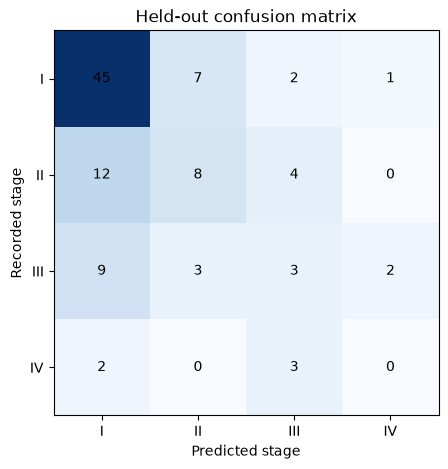

In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt
result = json.loads(Path("outputs/evaluation.json").read_text(encoding="utf-8"))
print("Cohort:", result["cases"], "cases;", result["genes"], "genes")
print("Class counts:", result["class_counts"])
print("Cross-validation macro F1:", result["cv_macro_f1"])
display(pd.DataFrame(result["test_report"]).T)
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(result["confusion_matrix"], cmap="Blues")
for i, row in enumerate(result["confusion_matrix"]):
    for j, count in enumerate(row):
        ax.text(j, i, str(count), ha="center", va="center")
ax.set(xticks=range(4), yticks=range(4), xticklabels=["I", "II", "III", "IV"], yticklabels=["I", "II", "III", "IV"], xlabel="Predicted stage", ylabel="Recorded stage", title="Held-out confusion matrix")
plt.show()

## Simpan grafik untuk dokumentasi

Grafik berikut dibuat dari hasil evaluasi ulang di atas. Feature importance bersifat global untuk model, bukan penjelasan pasien atau bukti sebab-akibat. Jangan memuat file model dari sumber yang tidak tepercaya.

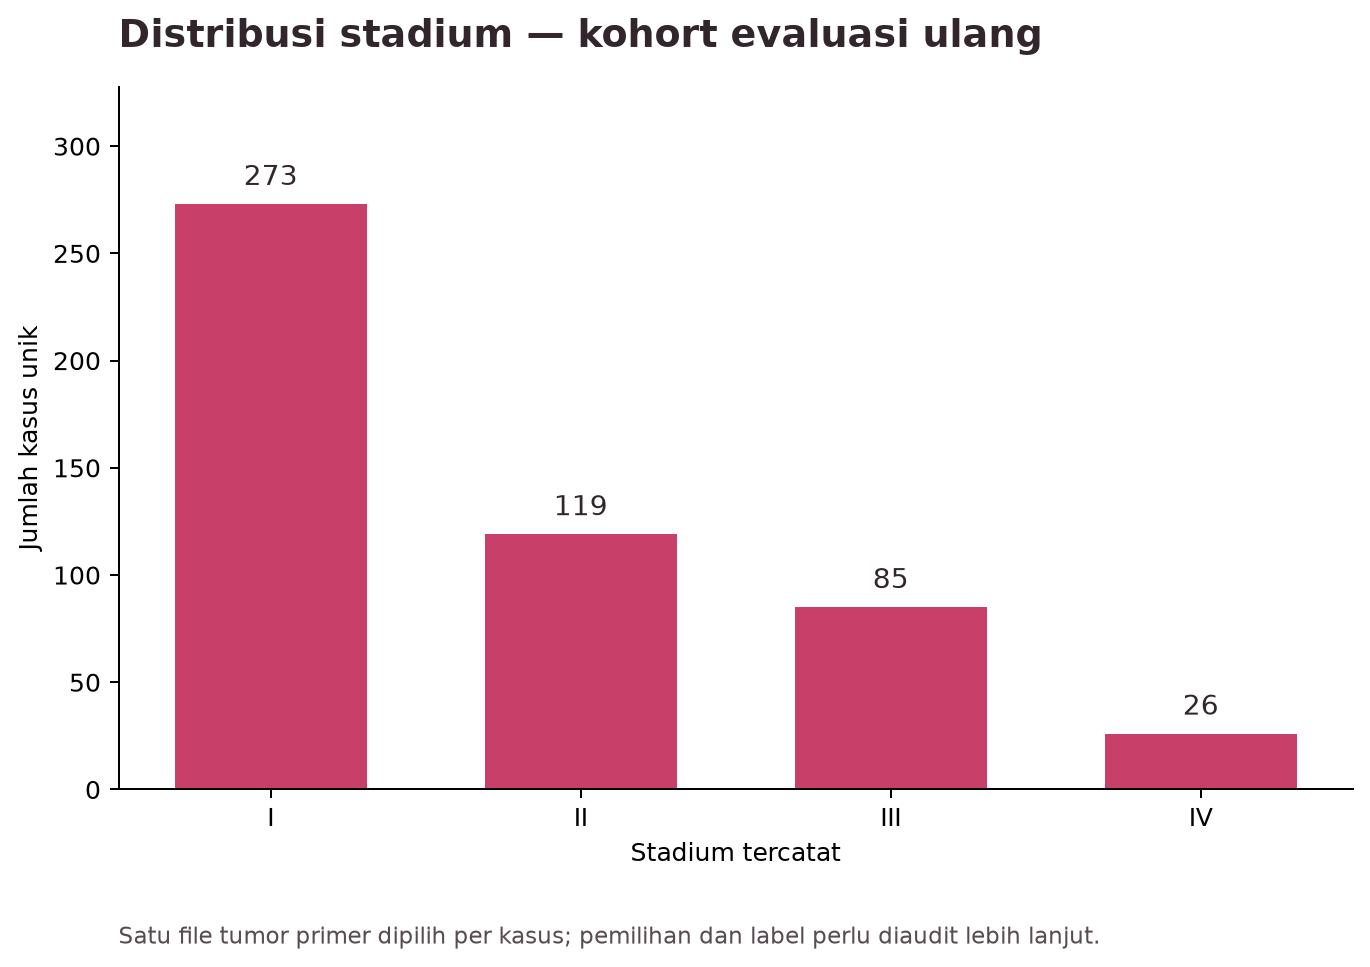

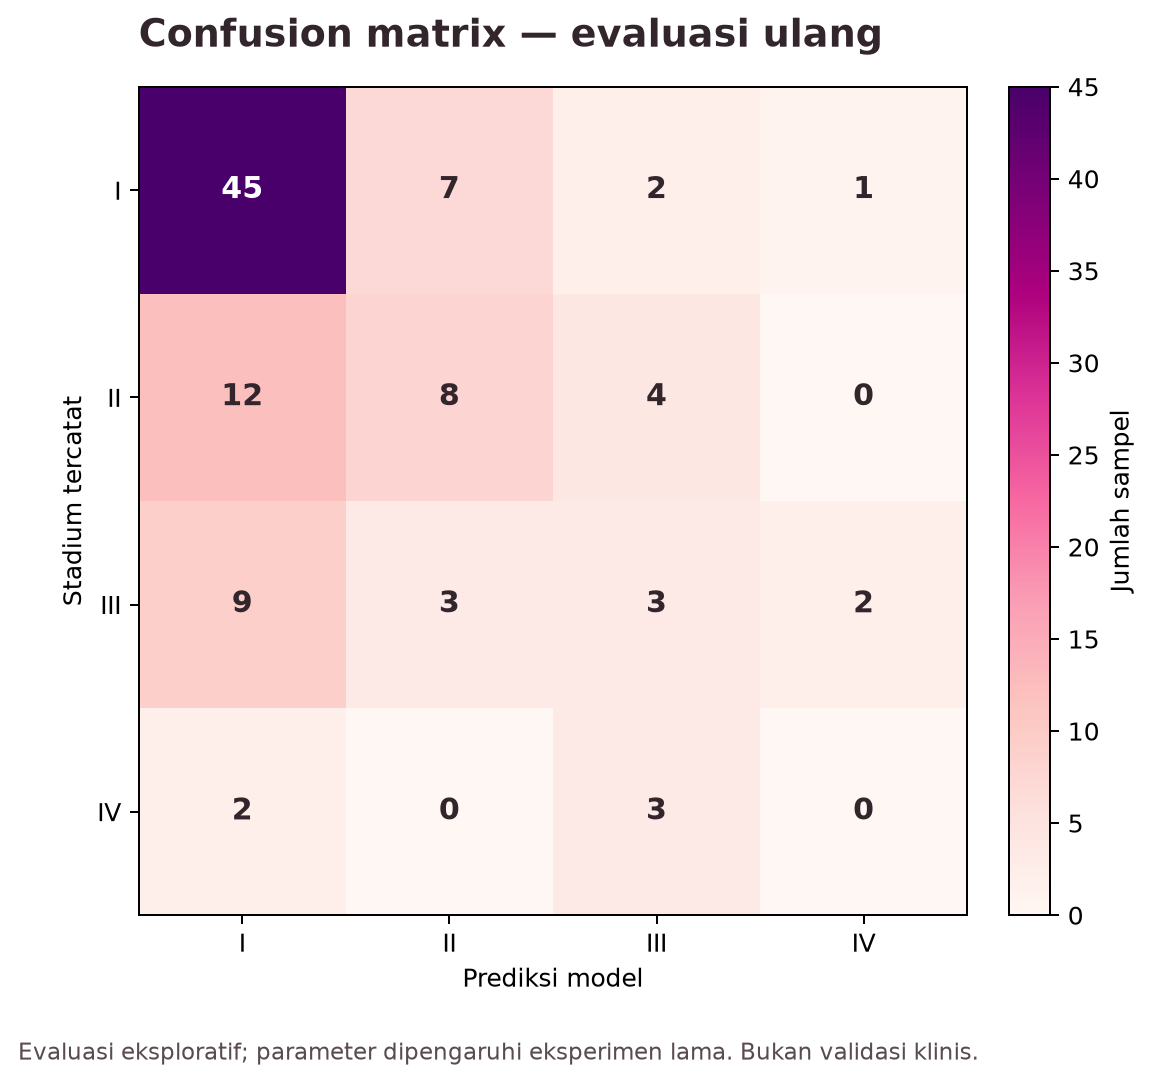

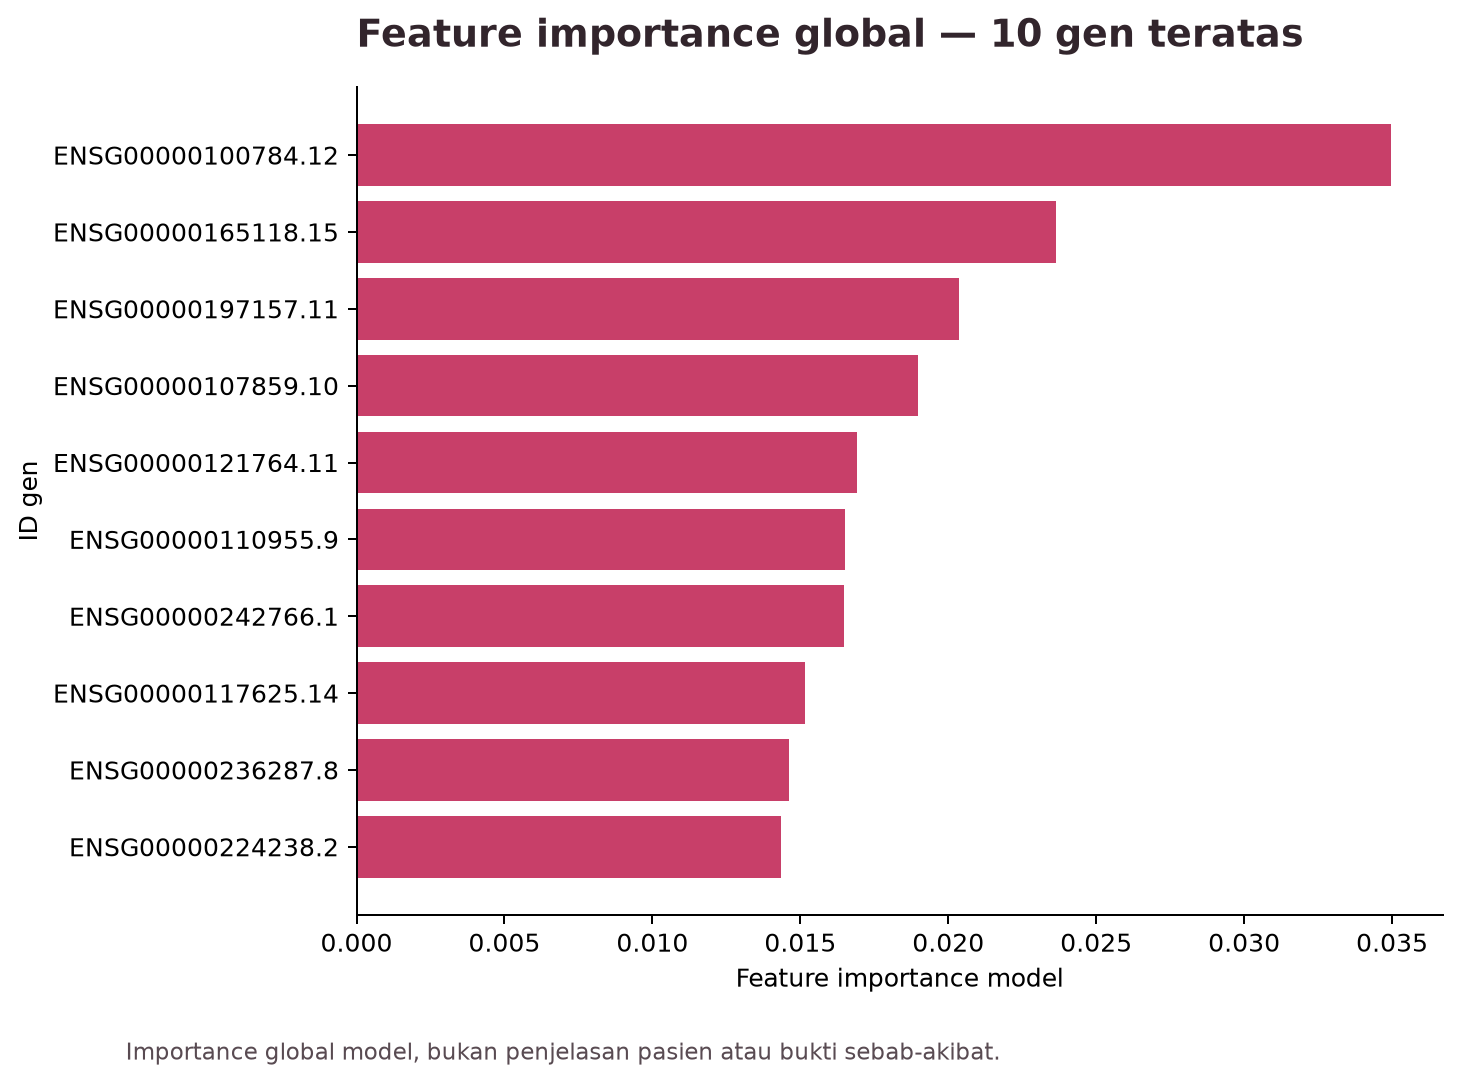

In [3]:
from IPython.display import Image, display
from plot_results import revised_figures
revised_figures()
for image in ["revised_class_distribution.png", "revised_confusion_matrix.png", "revised_global_importance.png"]:
    display(Image(filename=str(Path("figures") / image)))

## Interpretation of this evaluation

Compare class-specific results with the majority baseline; a small held-out class cannot support strong conclusions.

In [4]:
import json
from pathlib import Path
summary = json.loads(Path("outputs/evaluation.json").read_text(encoding="utf-8"))
held_out = summary["test_report"]
late_stage = held_out["3"]
print(f"Held-out cases: {int(held_out['macro avg']['support'])}")
print(f"Macro F1: {held_out['macro avg']['f1-score']:.3f}; majority baseline: {summary['majority_baseline_report']['macro avg']['f1-score']:.3f}")
print(f"Stage IV recall: {late_stage['recall']:.1%} of {int(late_stage['support'])} held-out cases")
print("Exploratory result, one split, small stage IV sample, and no clinical validation.")

Held-out cases: 101
Macro F1: 0.330; majority baseline: 0.176
Stage IV recall: 0.0% of 5 held-out cases
Exploratory result, one split, small stage IV sample, and no clinical validation.
